# Notebook 15: Aharonov–Bohm and Berry Phase, or Loop Phases in Γ

**Goal:** Γ is built from $|U_{ij}|^2$, so it throws phases away. Yet the Aharonov–Bohm effect and Berry's phase are phases with measurable consequences. Find which phases Γ
keeps, how it sees them, and whether they survive division events.

By the end of this notebook you will be able to:
- Separate phases that are gauge (Barandes's Schur–Hadamard gauge, of which lattice electromagnetic gauge is an immediate special case) from the one that is not: the flux around a loop
- Read the Aharonov–Bohm effect off one entry of Γ on a ring: $\cos^2(\Phi/2)$ at the opposite site
- Show that Γ can tell the sign of the flux only on rings with an odd number of sites
- Show that records erase the flux, gradually as records get stronger
- Recover Berry's phase (the solid angle) from Γ in the configuration basis, show that Γ(T ← 0) in the energy basis of the initial field is the identity, and that one record in the
  energy basis erases the fringe

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.loops import (ring_hamiltonian, gamma, recorded, dephased_populations, field_hamiltonian, loop_unitary,
                       energy_basis, fringe_phase, solid_angle)

## 1. Which Phases Are Gauge?

A particle hops around a ring of $N = 6$ sites; the hop from site $k$ to $k+1$ carries a phase $e^{i\varphi_k}$. In electromagnetism these phases come from the vector potential, and their sum
$\Phi = \sum_k \varphi_k$ is the magnetic flux through the ring.

Three ways to change phases:
- **Barandes's Schur–Hadamard gauge transformation** (*Quantum Systems as Indivisible Stochastic Processes*, §3.2): multiply each entry of the evolution matrix $\Theta(t \leftarrow 0)$ by its own
  phase. $\Gamma = |\Theta|^2$ cannot change, by construction.
- **An electromagnetic gauge transformation:** rephase each site, $H \to DHD^\dagger$. Then $\Theta \to D\Theta D^\dagger$: a Schur–Hadamard transformation with $\theta_{ij} = g_i - g_j$.
  Moving the flux from one bond to another is one of these. This is immediate from his eq. 30: a site rephasing is a diagonal $V$ in Barandes's dynamical-symmetry condition
  (Paper 3 §4.1, eq. 87), which every diagonal $V$ satisfies, and the same map is his Foldy–Wouthuysen gauge transformation (§3.6, eq. 74, with $V = D$). Barandes introduces his gauge
  by analogy with classical electromagnetism (§3.2) and does not discuss the lattice case.
- **Changing the flux** itself.

In [2]:
N, t = 6, 1.3
H_one = ring_hamiltonian(N, 0.9)                       # all the flux on the closing bond
H_uni = ring_hamiltonian(N, 0.9, gauge="uniform")      # the same flux spread over every bond
g = np.random.default_rng(0).uniform(0, 2 * np.pi, N)
D = np.diag(np.exp(1j * g))                             # a random electromagnetic gauge transformation

Theta = expm(-1j * H_one * t)
theta_ij = np.random.default_rng(1).uniform(0, 2 * np.pi, (N, N))
print(f"Schur–Hadamard phases on Θ(t):           max change in Γ = {np.abs(np.abs(Theta * np.exp(1j * theta_ij)) ** 2 - gamma(H_one, t)).max():.1e}")
print(f"flux moved to other bonds:               max change in Γ = {np.abs(gamma(H_uni, t) - gamma(H_one, t)).max():.1e}")
print(f"random site rephasing D H D†:             max change in Γ = {np.abs(gamma(D @ H_one @ D.conj().T, t) - gamma(H_one, t)).max():.1e}")
print(f"  ... and Θ → D Θ D† is Schur–Hadamard with θ_ij = g_i − g_j: "
      f"{np.allclose(expm(-1j * D @ H_one @ D.conj().T * t), Theta * np.exp(1j * (g[:, None] - g[None, :])))}")
print(f"flux 0.9 → 0:                            max change in Γ = {np.abs(gamma(ring_hamiltonian(N, 0.0), t) - gamma(H_one, t)).max():.3f}")
print(f"flux 0.9 → 0.9 + 2π:                     max change in Γ = {np.abs(gamma(ring_hamiltonian(N, 0.9 + 2 * np.pi), t) - gamma(H_one, t)).max():.1e}")

Schur–Hadamard phases on Θ(t):           max change in Γ = 8.3e-17
flux moved to other bonds:               max change in Γ = 3.3e-16
random site rephasing D H D†:             max change in Γ = 5.0e-16
  ... and Θ → D Θ D† is Schur–Hadamard with θ_ij = g_i − g_j: True
flux 0.9 → 0:                            max change in Γ = 0.042
flux 0.9 → 0.9 + 2π:                     max change in Γ = 0.0e+00


## 2. The Aharonov–Bohm Effect in One Entry of Γ

Start at site 0 and look at the opposite site, 3. There are two shortest routes, one round each side of the ring, and the flux sits between them. No site is inside the ring, so the particle
never visits the flux.

τ = 0.05:  Γ_30(Φ) / Γ_30(0) = 1.0000  0.7500  0.5000  0.2500  0.0000
τ = 0.2:  Γ_30(Φ) / Γ_30(0) = 1.0000  0.7500  0.5000  0.2500  0.0000
cos²(Φ/2):                  1.0000  0.7500  0.5000  0.2500  0.0000


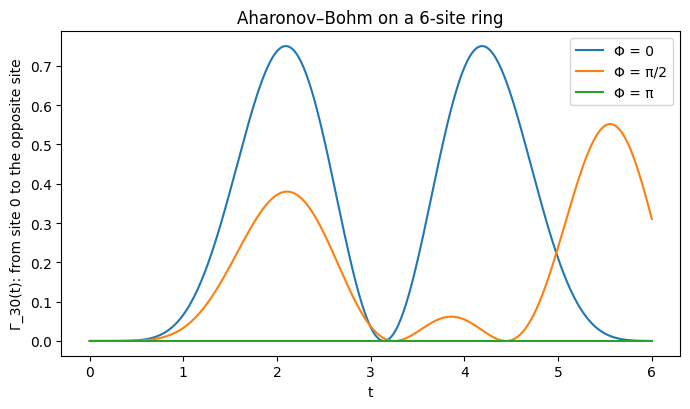

In [3]:
fluxes = [0, np.pi / 3, np.pi / 2, 2 * np.pi / 3, np.pi]
for tau in [0.05, 0.2]:
    base = gamma(ring_hamiltonian(N, 0.0), tau)[3, 0]
    ratios = [gamma(ring_hamiltonian(N, f), tau)[3, 0] / base for f in fluxes]
    print(f"τ = {tau}:  Γ_30(Φ) / Γ_30(0) = " + "  ".join(f"{r:.4f}" for r in ratios))
print(f"cos²(Φ/2):                  " + "  ".join(f"{np.cos(f / 2) ** 2:.4f}" for f in fluxes))

ts = np.linspace(0, 6, 400)
fig, ax = plt.subplots(figsize=(7, 4.2))
for f, lab in [(0, '0'), (np.pi / 2, 'π/2'), (np.pi, 'π')]:
    ax.plot(ts, [gamma(ring_hamiltonian(N, f), tt)[3, 0] for tt in ts], label=f'Φ = {lab}')
ax.set_xlabel('t'); ax.set_ylabel('Γ_30(t): from site 0 to the opposite site'); ax.set_title('Aharonov–Bohm on a 6-site ring'); ax.legend()
plt.tight_layout(); plt.show()

## 3. Can Γ Tell the Sign of the Flux?

Reversing the flux is time reversal, so $\Gamma(-\Phi) = \Gamma(\Phi)^{\mathsf T}$ exactly. If $\Gamma$ were symmetric it could not tell $\Phi$ from $-\Phi$. Measure the asymmetry $\max|\Gamma - \Gamma^{\mathsf T}|$ on
rings of different sizes.

On an even ring, flipping the sign of every other site is a gauge transformation taking $H$ to $-H$, and $\Gamma(-H) = \Gamma(H)^{\mathsf T}$, so Γ is symmetric for every flux
(the printout checks four fluxes; the annotated copy gives the argument in full).

In [4]:
print("check Γ(−Φ) = Γ(Φ)ᵀ on N = 5:", np.allclose(gamma(ring_hamiltonian(5, -0.7), 1.0), gamma(ring_hamiltonian(5, 0.7), 1.0).T))
print("\nmax |Γ − Γᵀ| at t = 1, for Φ = 0, π/4, π/2, π")
for n in [3, 4, 5, 6, 7]:
    row = [np.abs(gamma(ring_hamiltonian(n, f), 1.0) - gamma(ring_hamiltonian(n, f), 1.0).T).max() for f in [0, np.pi / 4, np.pi / 2, np.pi]]
    print(f"  N = {n} ({'odd ' if n % 2 else 'even'}):  " + "   ".join(f"{x:.3f}" for x in row))
print("\ntriangle, Φ = π/2, short times:  " + "   ".join(
    f"τ = {tau}: {np.abs(gamma(ring_hamiltonian(3, np.pi / 2), tau) - gamma(ring_hamiltonian(3, np.pi / 2), tau).T).max():.2e}"
    for tau in [0.05, 0.1, 0.2]))

check Γ(−Φ) = Γ(Φ)ᵀ on N = 5: True

max |Γ − Γᵀ| at t = 1, for Φ = 0, π/4, π/2, π
  N = 3 (odd ):  0.000   0.624   0.882   0.000
  N = 4 (even):  0.000   0.000   0.000   0.000
  N = 5 (odd ):  0.000   0.129   0.182   0.000
  N = 6 (even):  0.000   0.000   0.000   0.000
  N = 7 (odd ):  0.000   0.012   0.018   0.000

triangle, Φ = π/2, short times:  τ = 0.05: 2.50e-04   τ = 0.1: 1.99e-03   τ = 0.2: 1.55e-02


## 4. Records Erase the Flux

First dense records (notebook 11's division events every $\tau$, over a stretch of $1/\tau^2$ steps). Then weak records: after each step every coherence between configurations is
multiplied by $1 - \varepsilon$, from $\varepsilon = 0$ (no record) to $\varepsilon = 1$ (a full division event).

records every τ = 0.2:  6-site |Γ(Φ=0) − Γ(Φ=π)| = 6.8e-06    triangle asymmetry at Φ = π/2: 1.9e-02
records every τ = 0.1:  6-site |Γ(Φ=0) − Γ(Φ=π)| = 4.3e-07    triangle asymmetry at Φ = π/2: 9.9e-03
records every τ = 0.05:  6-site |Γ(Φ=0) − Γ(Φ=π)| = 2.7e-08    triangle asymmetry at Φ = π/2: 5.0e-03

weak records (τ = 0.1, 15 steps), Aharonov–Bohm visibility at the opposite site:
  ε=0.0: 1.000  ε=0.005: 0.982  ε=0.01: 0.965  ε=0.02: 0.930  ε=0.05: 0.830  ε=0.1: 0.676  ε=0.2: 0.428  ε=0.35: 0.198  ε=0.5: 0.088  ε=0.75: 0.020  ε=1.0: 0.001


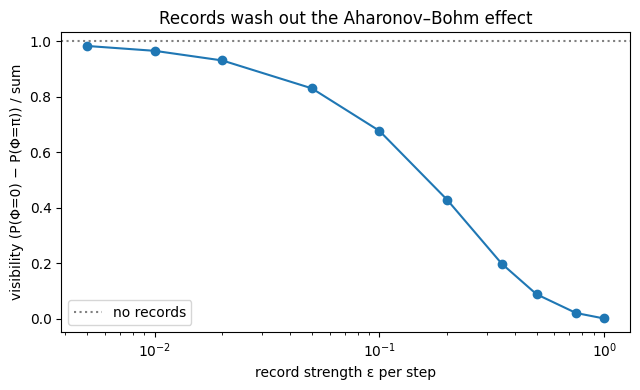

In [5]:
for tau in [0.2, 0.1, 0.05]:
    d6 = np.abs(recorded(ring_hamiltonian(6, 0.0), tau, 1.0) - recorded(ring_hamiltonian(6, np.pi), tau, 1.0)).max()
    C3 = recorded(ring_hamiltonian(3, np.pi / 2), tau, 1.0)
    print(f"records every τ = {tau}:  6-site |Γ(Φ=0) − Γ(Φ=π)| = {d6:.1e}    triangle asymmetry at Φ = π/2: {np.abs(C3 - C3.T).max():.1e}")

eps = np.array([0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0])
vis = []
for e in eps:
    p0 = dephased_populations(ring_hamiltonian(6, 0.0), 0.1, e, 15)[3]
    pp = dephased_populations(ring_hamiltonian(6, np.pi), 0.1, e, 15)[3]
    vis.append((p0 - pp) / (p0 + pp))
print("\nweak records (τ = 0.1, 15 steps), Aharonov–Bohm visibility at the opposite site:")
print("  " + "  ".join(f"ε={e}: {v:.3f}" for e, v in zip(eps, vis)))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(eps[1:], vis[1:], 'o-')
ax.axhline(vis[0], ls=':', color='grey', label='no records')
ax.set_xlabel('record strength ε per step'); ax.set_ylabel('visibility (P(Φ=0) − P(Φ=π)) / sum'); ax.set_title('Records wash out the Aharonov–Bohm effect'); ax.legend()
plt.tight_layout(); plt.show()

## 5. Berry's Phase

A spin-1/2 sits in a magnetic field of fixed strength $B_0$ that tilts at angle $\theta$ from the $z$ axis and goes once around $z$ in time $T$. The configurations are spin up and spin down along $z$.
Griffiths (§10.2.3) shows that each energy state picks up a geometric phase of minus half the solid angle swept by the field, $\Omega = 2\pi(1 - \cos\theta)$, the two states with opposite signs.

Three questions for Γ:
- In the **energy basis** of the initial (= final) field, what does Γ(T ← 0) look like after a slow loop?
- In the **configuration basis**, can Γ recover $\Omega$? A single Γ entry mixes Berry's phase with the much larger dynamical phase, so compare against a reference run with a *static*
  field of the same strength and duration, scanning $B_0T$: the loop shifts the fringe.
- What does one record in the energy basis, halfway round, do?

The test angles are chosen so that $\Omega$ mod $2\pi$ is neither 0 nor π. At $\theta = \pi/2$ the solid angle is $2\pi$, which shifts nothing; at $\pi/3$ and $2\pi/3$ it is π, where a shift of
$+\Omega$ and $-\Omega$ look the same. All four test angles, $\pi/6$, $\pi/4$, $3\pi/8$ and $3\pi/4$, test both the size and the sign of the shift (for each, $\Omega$ and $-\Omega$ differ
mod $2\pi$); $3\pi/4$ also tests a cone below the equator, where $\Omega > 2\pi$.

T =    20: Γ(T ← 0) in the energy basis of the initial field, off-diagonal = 9.5e-04
T =   200: Γ(T ← 0) in the energy basis of the initial field, off-diagonal = 4.6e-05
T =  2000: Γ(T ← 0) in the energy basis of the initial field, off-diagonal = 2.5e-07
T =   200: Γ(T/2 ← 0) in the same fixed basis, off-diagonal = 0.749   (sin²θ = 0.750)

fringe shift (loop vs static field) against the solid angle Ω (mod 2π):
  T =    200, θ = 0.524:  shift 0.786   Ω mod 2π 0.842
  T =    200, θ = 0.785:  shift 1.728   Ω mod 2π 1.840
  T =    200, θ = 1.178:  shift 3.683   Ω mod 2π 3.879
  T =    200, θ = 2.356:  shift 4.319   Ω mod 2π 4.443
  T =   2000, θ = 0.524:  shift 0.836   Ω mod 2π 0.842
  T =   2000, θ = 0.785:  shift 1.828   Ω mod 2π 1.840
  T =   2000, θ = 1.178:  shift 3.858   Ω mod 2π 3.879
  T =   2000, θ = 2.356:  shift 4.431   Ω mod 2π 4.443

T = 200, θ = π/4: fringe amplitude, loop 0.225;  with an energy-basis record at T/2 0.013
                  static field 0.250;  with an energy-b

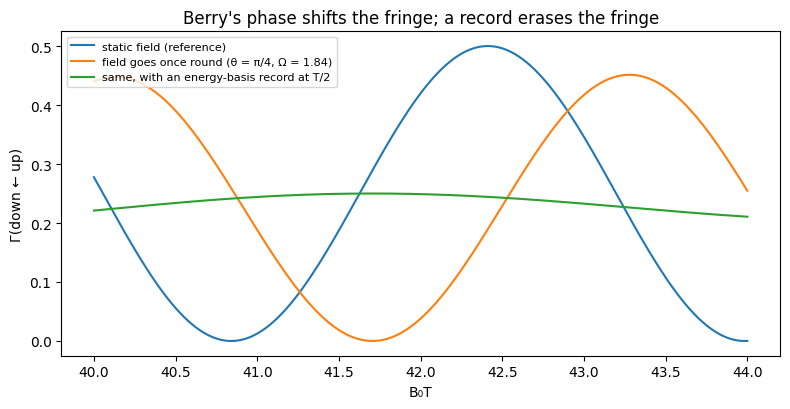

In [6]:
theta = np.pi / 3
for T in [20, 200, 2000]:
    V = energy_basis(1.0, theta)
    G_energy = np.abs(V.conj().T @ loop_unitary(1.0, theta, T) @ V) ** 2
    print(f"T = {T:5d}: Γ(T ← 0) in the energy basis of the initial field, off-diagonal = {G_energy[1, 0]:.1e}")
G_half = np.abs(V.conj().T @ loop_unitary(1.0, theta, 200, 0.5) @ V) ** 2
print(f"T =   200: Γ(T/2 ← 0) in the same fixed basis, off-diagonal = {G_half[1, 0]:.3f}   (sin²θ = {np.sin(theta) ** 2:.3f})")

print("\nfringe shift (loop vs static field) against the solid angle Ω (mod 2π):")
for T in [200.0, 2000.0]:
    for th in [np.pi / 6, np.pi / 4, 3 * np.pi / 8, 3 * np.pi / 4]:      # Ω mod 2π away from 0 and π, so size and sign both show
        x = np.linspace(0.2 * T, 0.2 * T + 4, 81)                      # B0 T values
        P_loop = np.array([abs(loop_unitary(v / T, th, T)[1, 0]) ** 2 for v in x])
        P_static = np.array([abs(expm(-1j * field_hamiltonian(v / T, th) * T)[1, 0]) ** 2 for v in x])
        shift = np.mod(fringe_phase(x, P_loop)[0] - fringe_phase(x, P_static)[0], 2 * np.pi)
        print(f"  T = {T:6.0f}, θ = {th:.3f}:  shift {shift:.3f}   Ω mod 2π {np.mod(solid_angle(th), 2 * np.pi):.3f}")

T, th = 200.0, np.pi / 4
x = np.linspace(40, 44, 161)
P_loop, P_static, P_rec, P_static_rec = [], [], [], []
record = lambda W, psi: W @ np.diag(np.abs(W.conj().T @ psi) ** 2) @ W.conj().T   # record which energy state
for v in x:
    B0 = v / T
    U_half, U = loop_unitary(B0, th, T, 0.5), loop_unitary(B0, th, T)
    rho = record(energy_basis(B0, th, np.pi), U_half @ np.array([1, 0]))  # energy states halfway round
    U_rest = U @ np.linalg.inv(U_half)
    P_rec.append((U_rest @ rho @ U_rest.conj().T)[1, 1].real)
    P_loop.append(abs(U[1, 0]) ** 2)
    S_half = expm(-1j * field_hamiltonian(B0, th) * T / 2)               # static field: same record, no loop
    rho_s = record(energy_basis(B0, th), S_half @ np.array([1, 0]))
    P_static_rec.append((S_half @ rho_s @ S_half.conj().T)[1, 1].real)
    P_static.append(abs(expm(-1j * field_hamiltonian(B0, th) * T)[1, 0]) ** 2)
print(f"\nT = 200, θ = π/4: fringe amplitude, loop {fringe_phase(x, np.array(P_loop))[1]:.3f};"
      f"  with an energy-basis record at T/2 {fringe_phase(x, np.array(P_rec))[1]:.3f}")
print(f"                  static field {fringe_phase(x, np.array(P_static))[1]:.3f};"
      f"  with an energy-basis record at T/2 {fringe_phase(x, np.array(P_static_rec))[1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x, P_static, label='static field (reference)')
ax.plot(x, P_loop, label=f'field goes once round (θ = π/4, Ω = {solid_angle(th):.2f})')
ax.plot(x, P_rec, label='same, with an energy-basis record at T/2')
ax.set_xlabel('B₀T'); ax.set_ylabel('Γ(down ← up)'); ax.set_title("Berry's phase shifts the fringe; a record erases the fringe"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. A Non-Abelian Flux: SU(2) Links (added 2026-11-11)

Give the particle a two-valued internal label, "colour", and let each hop multiply it by a 2×2 SU(2) matrix instead of a phase. The configurations are (site, colour). Three checks:
- **Is an SU(2) gauge transformation (rotating colour at each site) a Schur–Hadamard gauge?** In Barandes's framework this is the dynamical-symmetry test of Paper 3 §4.1
  (eqs. 85–87): with the configuration projectors held fixed, $V\Theta V^\dagger$ describes the same process if and only if it differs from Θ by a Schur–Hadamard transformation. (If the
  projectors are rotated too, it is his Foldy–Wouthuysen gauge transformation, §3.6 eq. 74, which leaves Γ unchanged by construction.) Holding the colour basis fixed as the
  configurations, compare Γ before and after.
- **One ring.** The loop product is now a matrix $W$, with eigenphases $\pm\varphi$. Does Γ on the sites (colour averaged) see the orientation of the loop, as an abelian flux does on odd rings?
- **Two loops.** With each loop's trace held fixed, does Γ see the trace of the product $W_1W_2$, which has no abelian counterpart?

Spike and fuller output: `notes/su2-lattice-spike-2026-11-11.md`.

In [7]:
rng = np.random.default_rng(11)
S = [np.array([[0, 1], [1, 0]], complex), np.array([[0, -1j], [1j, 0]]), np.diag([1.0 + 0j, -1.0])]
su2 = lambda a, n: expm(1j * a * sum(c * s for c, s in zip(np.asarray(n) / np.linalg.norm(n), S)))
rand_su2 = lambda: su2(rng.uniform(0, np.pi), rng.normal(size=3))
times = np.linspace(0.1, 6, 30)

def link_H(n_sites, edges, links):
    d = links[0].shape[0]
    H = np.zeros((n_sites * d, n_sites * d), complex)
    for (i, j), U in zip(edges, links):
        H[d*j:d*j+d, d*i:d*i+d] += -U
        H[d*i:d*i+d, d*j:d*j+d] += -U.conj().T
    return H

def site_gamma(H, t, d=2):        # colour-averaged: start in a random colour, ignore the final colour
    G = gamma(H, t)
    n = len(G) // d
    return G.reshape(n, d, n, d).sum(axis=(1, 3)) / d

ring5 = [(i, (i + 1) % 5) for i in range(5)]
H = link_H(5, ring5, [rand_su2() for _ in range(5)])
Gm = np.zeros_like(H)
for i in range(5):
    Gm[2*i:2*i+2, 2*i:2*i+2] = rand_su2()                      # rotate colour at each site
Hg = Gm @ H @ Gm.conj().T
print("SU(2) gauge, 5-ring:")
print(f"  colour-resolved Γ changes by up to  {max(np.abs(gamma(H, t) - gamma(Hg, t)).max() for t in times):.3f}")
print(f"  colour-averaged site Γ changes by   {max(np.abs(site_gamma(H, t) - site_gamma(Hg, t)).max() for t in times):.1e}")

phi = 1.3
W = su2(phi, [1, 2, 3])
H = link_H(5, ring5, [np.eye(2, dtype=complex)] * 4 + [W])
asym = max(np.abs(site_gamma(H, t) - site_gamma(H, t).T).max() for t in times)
abel = max(np.abs(gamma(ring_hamiltonian(5, phi), t) - gamma(ring_hamiltonian(5, phi), t).T).max() for t in times)
print(f"\none 5-ring, loop eigenphases ±{phi}: orientation signal |Γ − Γᵀ|  SU(2) {asym:.1e}   abelian flux {phi}: {abel:.3f}")

edges = [(0, 1), (1, 2), (0, 3), (1, 4), (2, 5), (3, 4), (4, 5)]   # 2×3 ladder: two plaquettes
a, I2 = 1.1, np.eye(2, dtype=complex)
base = None
print("\ntwo plaquettes, Tr W1 = Tr W2 = 2cos(1.1) fixed, angle β between their axes:")
for beta in [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi]:
    W1, W2 = su2(a, [0, 0, 1]), su2(a, [np.sin(beta), 0, np.cos(beta)])
    Gs = [site_gamma(link_H(6, edges, [I2] * 5 + [W1, W2]), t) for t in times]
    base = Gs if base is None else base
    print(f"  β = {beta:.2f}: Tr(W1 W2) = {np.trace(W1 @ W2).real:+.3f}   Γ_site moves by "
          f"{max(np.abs(x - y).max() for x, y in zip(Gs, base)):.3f}")

SU(2) gauge, 5-ring:
  colour-resolved Γ changes by up to  0.268
  colour-averaged site Γ changes by   9.4e-16

one 5-ring, loop eigenphases ±1.3: orientation signal |Γ − Γᵀ|  SU(2) 1.8e-15   abelian flux 1.3: 0.798

two plaquettes, Tr W1 = Tr W2 = 2cos(1.1) fixed, angle β between their axes:
  β = 0.00: Tr(W1 W2) = -1.177   Γ_site moves by 0.000
  β = 0.79: Tr(W1 W2) = -0.712   Γ_site moves by 0.343
  β = 1.57: Tr(W1 W2) = +0.411   Γ_site moves by 0.722
  β = 2.36: Tr(W1 W2) = +1.535   Γ_site moves by 0.815
  β = 3.14: Tr(W1 W2) = +2.000   Γ_site moves by 0.967


## Summary

- **Γ sees phases only around loops.** Arbitrary phases on the entries of the evolution matrix are gauge (Barandes's Schur–Hadamard gauge); lattice electromagnetic gauge transformations are
  the special case $\theta_{ij} = g_i - g_j$ (immediate from his eq. 30: a diagonal $V$ in his §4.1 condition, eq. 87, and his Foldy–Wouthuysen gauge, §3.6, with $V = D$; Barandes
  introduces his gauge by analogy with classical electromagnetism, §3.2, and does not discuss the lattice case). What is left is the flux, the loop product of the hopping phases, and it changes Γ. This is the lattice version of Peskin's statement that gauge-invariant
  functions of the potential are built from Wilson loops.
- **The Aharonov–Bohm effect is one entry of Γ.** At the opposite site of a 6-site ring, $\Gamma_{30}(\Phi)/\Gamma_{30}(0) = \cos^2(\Phi/2)$ at short times (to 4 decimals at both printed times); at $\Phi = \pi$, $\Gamma_{30}$ vanishes at all times (the $\Phi = \pi$ curve in the plot stays at zero). The particle's configurations
  never include the flux.
- **The sign of the flux is visible only on odd rings.** $\Gamma(-\Phi) = \Gamma(\Phi)^{\mathsf T}$ always; on even rings Γ is symmetric for every flux (the sublattice sign flip, section 3), the Γ(H) = Γ(−H) blindness of notebook 12.
- **Records erase the flux.** Dense records give a flux-blind random walk; weak records reduce the Aharonov–Bohm visibility smoothly from 1 to 0.
- **Berry's phase.** In the energy basis of the initial (= final) field, Γ(T ← 0) is the identity after a slow loop, blind to Berry's phase. (Only in the instantaneous energy basis, which
  turns with the field, is Γ(t ← 0) ≈ 1 at every t; in the fixed basis Γ(T/2 ← 0) has off-diagonal ≈ sin²θ, so the process is not divisible at T/2.) In the configuration basis the loop
  shifts the fringe by the solid angle Ω, approaching it as $1/T$ (at $T = 2000$: 0.836, 1.828, 3.858, 4.431 against Ω mod 2π = 0.842, 1.840, 3.879, 4.443). One record in the
  energy basis halfway round erases the fringe (amplitude 0.225 → 0.013; the remainder is non-adiabatic), not only Berry's shift: the same record on a static field erases its fringe too. That is a property of records, not of Berry's phase.
- **Non-abelian links (section 6).** Rotating colour site by site fails Barandes's dynamical-symmetry condition (Paper 3 §4.1, eq. 86) when colour is a configuration: it changes the
  colour-resolved Γ (by up to 0.27 for this random draw; 0.54 in the spike's), while the colour-averaged site Γ is unchanged. So if local SU(2) rotations are to be a redundancy, as in
  lattice gauge theory, colour cannot serve as a configuration; only colour-blind quantities can. An SU(2) loop
  cannot show its orientation even on an odd ring (every SU(2) matrix is equivalent to its inverse), and with two loops Γ sees the trace of their product. All of this is standard
  non-abelian gauge physics restated in Γ language.
- **So** the phases Γ can see are loop phases, and it sees them only through interference within indivisible stretches, the same pattern as the exchange interference of notebook 14.

Caveats: one particle, small rings, one spin; the fringe comparison needs a reference run, as Griffiths' beam-splitter argument does.

Prior work: that loop phases are the only gauge invariants of the hopping phases, and that Γ(−Φ) = Γ(Φ)ᵀ with no sign information on even (bipartite) rings, are known from the
chiral-quantum-walk literature (Zimborás et al. (2013); Lu et al., arXiv:1405.6209). The cos²(Φ/2) visibility is the textbook Aharonov–Bohm result; records erasing it is Stern, Aharonov and Imry (1990);
the Berry fringe is Berry (1984). Antonakos and Terzis (2023) treat Aharonov–Bohm in Nelson's stochastic mechanics. No ISP treatment of Aharonov–Bohm or Berry was found
in the 2026-10-29 search; the notebook restates known physics in Γ language.